# This is a notebook that predicts car used car value from Craigslist

### About the project
Craigslist is the world's largest collection of used vehicles for sale. Using data from this platform, this notebook will create a ML model to predict the true value of an used car based on its features.

Data is coming from [kaggle](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data) and contains 26 features.

### Project Steps
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis
- Feature Engineering
- Model development
- Results

### Step 0: Environment creation

This step involvees download of the required packages and their import into the working environment

In [2]:
#%pip install numpy; pandas; matplotlib; scikit-learn; kagglehub; xgboost

In [3]:
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 1: Data Collection

Data will be downloaded from kaggle

Dataset features: <StringArray>
[          'id',          'url',       'region',   'region_url',
        'price',         'year', 'manufacturer',        'model',
    'condition',    'cylinders',         'fuel',     'odometer',
 'title_status', 'transmission',          'VIN',        'drive',
         'size',         'type',  'paint_color',    'image_url',
  'description',       'county',        'state',          'lat',
         'long', 'posting_date']
Length: 26, dtype: str
<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 

<Axes: >

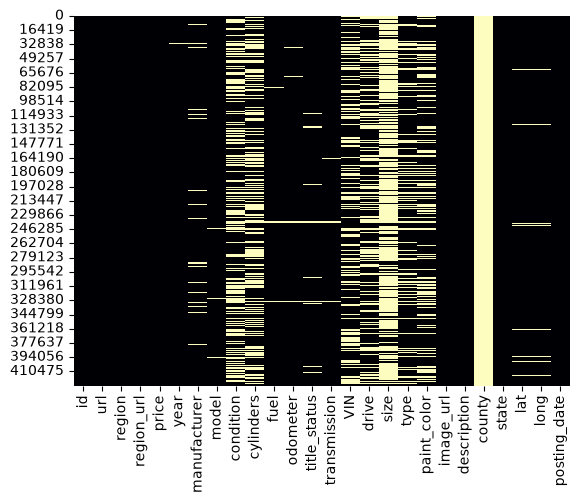

In [4]:
handle = 'austinreese/craigslist-carstrucks-data'
output_dir = 'Data'

#dataset = kagglehub.dataset_download(handle=handle, output_dir=output_dir)

df = pd.read_csv(f'{output_dir}\\vehicles.csv')
df.head()

print('Dataset features:', df.columns.values)
print('Dataset info:', df.info())
print('Null values:', df.isna().sum())
sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

#### Data collection conclusions
- There are a lot of missing values
- County column has no valu so it will be the first to be dropped
- Few numeric values:
    - useful: price(target), year, odometer
    - not useful: id, county, lat and long
- Loads of categorical features - need to check which one will have impact
- Condition feature has loads of missing values
- Cylinder feature can be mapped from string to numeric value

### Step 2: Data preparation

<Axes: >

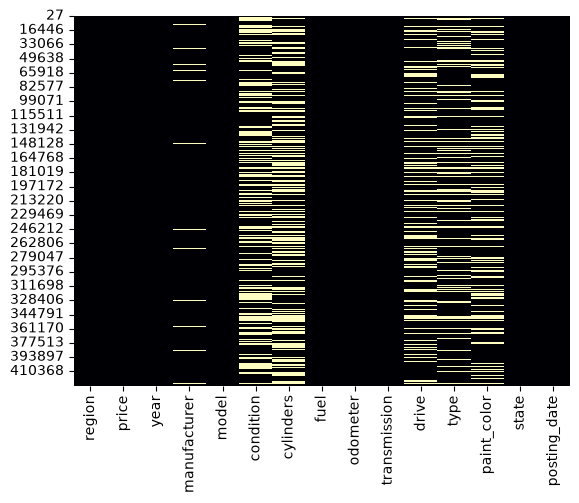

In [10]:
#Eliminate irrelevant features
irrelevant_features = ['id', 'url', 'region_url', 'title_status', 'VIN', 'image_url', 'description', 'lat', 'long']

df = df.drop(columns=irrelevant_features, errors='ignore')

#Create a visualization of missing data
sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

#Determine how much of each feature is nan and remove features with more than 50% missing values
length = len(df)
cutoff = 50 #Will discard data with cutoff values over 50%
col_missing_over_cutoff = []

for column in df.columns.values:
    missing_percent = (df[column].isna().sum()/length)*100
    if missing_percent > 50:
        col_missing_over_cutoff.append(column)

df = df.drop(columns = col_missing_over_cutoff)

#Drop rows with missing data for columns: year, model, fuel, odometer and transmision since there are few missing values

df = df.dropna(subset=['year', 'model', 'fuel', 'odometer', 'transmission'])

sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

Based on the remaining features and their missing values I can do the following things:
- There are columns where few values are missing
    - for year, model fuel odometer and transmision just drop the rows
    - for manufacturer I can determine it based on the model - but it might not bring new info to the model
- There are columns where loads of values are missing
    - paint color could be ignored for the moment.
    - I guess that drive, type and possiblly cylinders are missing when only one possibility exists
    - Exploratory Data Analysis needs to be performed to understand the data better

### Step 3: Exploratory Data Analysis

In this step multiple visualizations will be created to understand how features relate to the target and to each other.
Another important step is to check the relation of missing values to the rest of the features

#### Price distribution

Firstly a price histogram is created to understand how the target is distributed

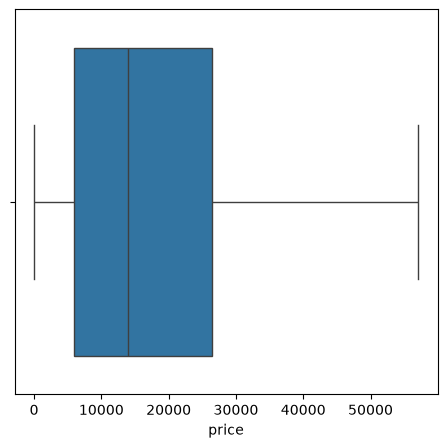

In [43]:
# price = df['price']

# q1 = price.quantile(q=0.25)
# q3 = price.quantile(q=0.75)
# iqr = q3 - q1
# upper = q3 + 1.5*iqr

# price_for_plot = price[price<=upper]

# print(f"Number of values remaining are: {len(price_for_plot)}")
# price_for_plot.plot.hist(bins=50, title="Price distribution (IQR-filtered for display)")

fig = plt.figure(figsize=(12, 5))
ax1 = plt.subplot(1, 2, 1)

# ax1 = sns.histplot(data=df, x='price', bins=10)
ax1 = sns.boxplot(data=df, x='price', showfliers=False)


Time to check the cylinders feature

In [45]:
df_colorado = df[df['model'] == 'colorado crew cab z71']
df_colorado.head(15)
# df_colorado['cylinders'].value_counts()
# df_colorado['drive'].value_counts()
df['year'].value_counts()

year
2018.0    35506
2017.0    35463
2015.0    30520
2013.0    29947
2016.0    29454
          ...  
1943.0        1
1915.0        1
1902.0        1
1905.0        1
1909.0        1
Name: count, Length: 113, dtype: int64

C:\Users\Rober\AppData\Local\Temp\ipykernel_6140\3688668608.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, ha="right",fontsize=8)


[Text(0, 0, '1985.0'),
 Text(1, 0, '1986.0'),
 Text(2, 0, '1987.0'),
 Text(3, 0, '1988.0'),
 Text(4, 0, '1989.0'),
 Text(5, 0, '1990.0'),
 Text(6, 0, '1991.0'),
 Text(7, 0, '1992.0'),
 Text(8, 0, '1993.0'),
 Text(9, 0, '1994.0'),
 Text(10, 0, '1995.0'),
 Text(11, 0, '1996.0'),
 Text(12, 0, '1997.0'),
 Text(13, 0, '1998.0'),
 Text(14, 0, '1999.0'),
 Text(15, 0, '2000.0'),
 Text(16, 0, '2001.0'),
 Text(17, 0, '2002.0'),
 Text(18, 0, '2003.0'),
 Text(19, 0, '2004.0'),
 Text(20, 0, '2005.0'),
 Text(21, 0, '2006.0'),
 Text(22, 0, '2007.0'),
 Text(23, 0, '2008.0'),
 Text(24, 0, '2009.0'),
 Text(25, 0, '2010.0'),
 Text(26, 0, '2011.0'),
 Text(27, 0, '2012.0'),
 Text(28, 0, '2013.0'),
 Text(29, 0, '2014.0'),
 Text(30, 0, '2015.0'),
 Text(31, 0, '2016.0'),
 Text(32, 0, '2017.0'),
 Text(33, 0, '2018.0'),
 Text(34, 0, '2019.0'),
 Text(35, 0, '2020.0'),
 Text(36, 0, '2021.0'),
 Text(37, 0, '2022.0')]

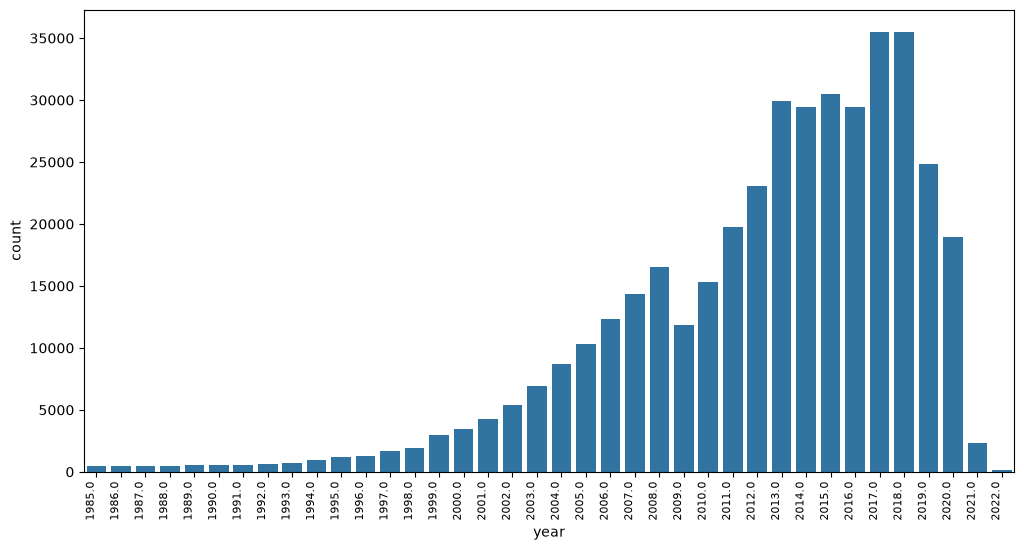

In [56]:
fig = plt.figure(figsize=(12, 6))
# ax = sns.countplot(x='year',data=df)
# ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right",fontsize=6)

df_1980 = df[df['year']>=1985.0]
len(df_1980)

ax1 = sns.countplot(x='year',data=df_1980)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, ha="right",fontsize=8)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [Text(0, 0, 'land rover'),
  Text(1, 0, 'aston-martin'),
  Text(2, 0, 'datsun'),
  Text(3, 0, 'ferrari'),
  Text(4, 0, 'harley-davidson'),
  Text(5, 0, 'fiat'),
  Text(6, 0, 'tesla'),
  Text(7, 0, 'alfa-romeo'),
  Text(8, 0, 'saturn'),
  Text(9, 0, 'mercury'),
  Text(10, 0, 'porsche'),
  Text(11, 0, 'rover'),
  Text(12, 0, 'jaguar'),
  Text(13, 0, 'pontiac'),
  Text(14, 0, 'mini'),
  Text(15, 0, 'mitsubishi'),
  Text(16, 0, 'volvo'),
  Text(17, 0, 'lincoln'),
  Text(18, 0, 'infiniti'),
  Text(19, 0, 'mazda'),
  Text(20, 0, 'buick'),
  Text(21, 0, 'chrysler'),
  Text(22, 0, 'acura'),
  Text(23, 0, 'cadillac'),
  Text(24, 0, 'audi'),
  Text(25, 0, 'lexus'),
  Text(26, 0, 'kia'),
  Text(27, 0, 'volkswagen'),
  Text(28, 0, 'subaru'),
  Text(29, 0, 'hyundai

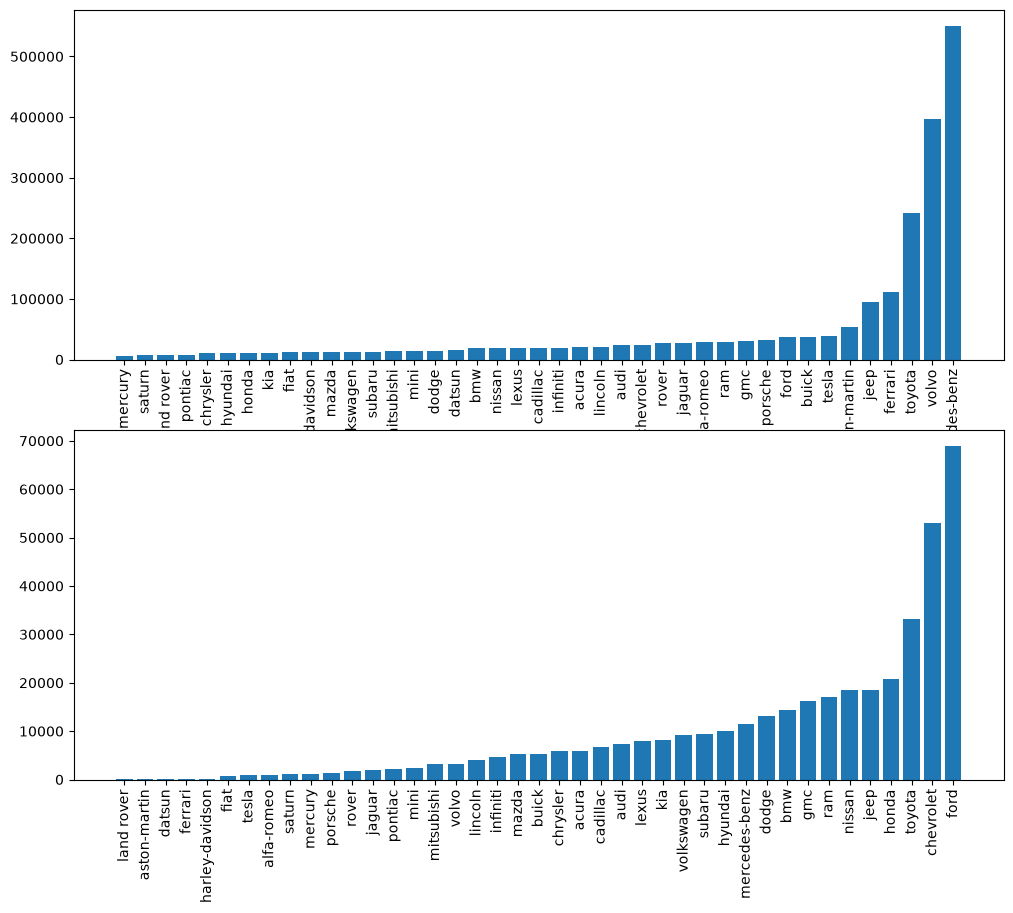

In [66]:
plt.figure(figsize=(12,10))

df_manuf_price = df.groupby('manufacturer')['price'].mean().reset_index().sort_values(by='price')
plt.subplot(2, 1, 1)
plt.bar(x=df_manuf_price['manufacturer'], height=df_manuf_price['price'])
plt.xticks(rotation=90)

df_manuf_listings = df.groupby('manufacturer')['posting_date'].count().reset_index().sort_values(by='posting_date')
plt.subplot(2, 1, 2)
plt.bar(x=df_manuf_listings['manufacturer'], height=df_manuf_listings['posting_date'])
plt.xticks(rotation=90)


In [68]:
unique_models = df['model'].unique()
unique_models_count = len(unique_models)
unique_models_count

28539